# Bab 4 — Membangun Model dengan Metrik Jarak dan *Nearest Neighbors*

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025), Bab 4
**Sumber kode:** [PacktPublishing/Scikit-Learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition) (`Chapter_4`)
**Direproduksi dan dijelaskan oleh:** Tarannia Raisha Putri — NIM 101032300231 — S1 Teknik Komputer, Telkom University

**Resep yang dibahas**

| # | Resep | Alat utama |
|---|--------|-----------|
| 4.1 | Memahami *k-Nearest Neighbors* (KNN) | `KNeighborsClassifier`, `accuracy_score` |
| 4.2 | Gambaran Metrik Jarak | `metric="euclidean" / "manhattan" / "minkowski"`, `make_circles` |
| 4.3 | *Tuning* Hiperparameter KNN | `GridSearchCV` |
| 4.4 | Mengevaluasi Kinerja KNN | `cross_val_score`, `learning_curve`, `confusion_matrix`, `classification_report` |
| 4.5 | Latihan Praktis Model KNN | KNN + `StandardScaler` pada Breast Cancer dan data sintetis |

> Nomor resep ditambahkan di sini untuk memudahkan navigasi; buku aslinya tidak menomori resep. Resep 4.5 memakai solusi resmi dari notebook *Exercise Solution* di repositori.

## Gambaran Umum Bab

*k-nearest neighbors* adalah cara paling langsung untuk mengubah gagasan *kemiripan* menjadi prediksi: untuk memberi label pada titik baru, lihat titik-titik berlabel yang paling dekat dengannya dan biarkan mereka memberi suara. Tidak ada pelatihan dalam arti biasa. Model *adalah* data yang disimpan ditambah definisi "dekat". Hal ini menjadikan KNN model yang ideal untuk mempelajari bahan-bahan yang diandalkan setiap metode berbasis jarak: **metrik jarak**, **jumlah tetangga** dan cara **pembobotannya**, serta cara **men-*tuning* dan mengevaluasi** pilihan-pilihan itu secara jujur.

Bab ini membangun *classifier* KNN dasar, membandingkan metrik jarak pada dua geometri sintetis, men-*tuning* hiperparameter dengan *grid search* ber-*cross-validation*, lalu mengevaluasi model hasil *tuning* dengan skor *cross-validation*, kurva belajar (*learning curve*), *confusion matrix*, serta *precision/recall/F1* per kelas. Alat evaluasi dan *tuning* ini muncul kembali di setiap bab berikutnya. Dalam *pipeline* ML, bab ini berada di tahap *pemodelan + pemilihan model* dan dibangun langsung di atas Bab 2 (KNN tidak bermakna tanpa penskalaan fitur) dan Bab 3 (jarak makin tidak informatif di dimensi tinggi).

## Persiapan

In [1]:
# Pustaka inti yang dipakai di sepanjang bab ini
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

# Satu seed global agar setiap eksekusi notebook menghasilkan angka yang sama.
# (Sel-sel buku tetap memakai nilai random_state masing-masing.)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Catat lingkungan persis yang menghasilkan output di bawah
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

Python       : 3.13.5
numpy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.4


## Resep 4.1 — Memahami *k-Nearest Neighbors* (KNN)

**Tujuan.** Membangun dan mengevaluasi *classifier* KNN dasar yang memprediksi spesies bunga iris dari keempat ukurannya.

### Teori

**Intuisi.** "Katakan siapa tetanggamu, maka akan kukatakan siapa dirimu." Untuk mengklasifikasikan bunga baru, cari $k$ bunga latih dengan ukuran yang paling mirip dan prediksi spesies yang paling banyak di antara mereka. $k$ yang kecil mengikuti data dengan ketat (fleksibel, tetapi sensitif terhadap *noise*). $k$ yang besar merata-ratakan wilayah yang lebih luas (lebih halus, tetapi bisa mengaburkan batas kelas).

**Matematika.** Diberikan pasangan latih $\{(\mathbf{x}_i, y_i)\}_{i=1}^n$, jarak $d(\cdot,\cdot)$, dan titik kueri $\mathbf{x}$, misalkan $N_k(\mathbf{x})$ adalah indeks $k$ titik latih yang paling dekat dengan $\mathbf{x}$.

* *Klasifikasi (bobot seragam):* estimasi peluang kelas adalah $\hat{P}(y=c\mid\mathbf{x}) = \frac{1}{k}\sum_{i\in N_k(\mathbf{x})}\mathbb{1}[y_i=c]$, dan prediksinya $\hat{y}=\arg\max_c \hat{P}(y=c\mid\mathbf{x})$ (suara terbanyak).
* *Bobot jarak:* setiap tetangga memberi suara dengan bobot $w_i = 1/d(\mathbf{x},\mathbf{x}_i)$, sehingga tetangga yang lebih dekat lebih berpengaruh.
* *Regresi:* $\hat{y}=\frac{1}{k}\sum_{i\in N_k(\mathbf{x})} y_i$ (atau rata-rata berbobot).

**Cara scikit-learn mengimplementasikannya.** `KNeighborsClassifier(n_neighbors=5, weights="uniform", algorithm="auto", leaf_size=30, p=2, metric="minkowski")`.

* `fit` tidak mempelajari parameter. Ia menyimpan data latih dan, tergantung `algorithm`, membangun struktur pencarian (`"kd_tree"`, `"ball_tree"`) atau menyimpan array mentah untuk pencarian `"brute"`. `"auto"` memilih berdasarkan ukuran dan dimensi data.
* `predict` mencari $k$ titik tersimpan terdekat untuk setiap kueri dan mengambil suara (berbobot). `predict_proba` mengembalikan porsi suara.
* `KNeighborsRegressor` memiliki antarmuka yang sama dan merata-ratakan target alih-alih melakukan voting.

**Asumsi, kelebihan, keterbatasan.**

* *Non-parametrik:* tidak ada asumsi tentang bentuk batas keputusan, dan menangani masalah multikelas secara alami.
* *Lazy:* pelatihan instan, tetapi prediksi memerlukan pencarian di seluruh data latih, yang mahal untuk dataset besar.
* Secara implisit mengasumsikan bahwa **jarak mencerminkan kemiripan**. Fitur harus berada pada skala yang sebanding (Bab 2), dan fitur yang tidak relevan menambah *noise* ke setiap jarak.
* Terkena **curse of dimensionality**: di banyak dimensi semua titik menjadi kira-kira sama jauhnya, sehingga "terdekat" kehilangan makna.
* Cocok untuk data kecil/menengah berdimensi rendah dengan jarak yang bermakna. Kurang cocok untuk data besar, berdimensi tinggi, atau berjenis campuran.

### Kode

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Iris: 150 bunga, 4 ukuran (cm), 3 spesies
iris = load_iris()
X = iris.data
y = iris.target

# Pembagian 80/20 -> 120 bunga latih / 30 bunga uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2024
)

In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Voting di antara 3 bunga latih terdekat (default Minkowski p=2 = Euclidean)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9333333333333333


In [4]:
# Keseimbangan kelas data uji, konteks yang berguna untuk akurasi (tambahan)
print("ukuran latih:", len(y_train), "| ukuran uji:", len(y_test))
print("sampel uji per kelas:", {str(n): int(c) for n, c in zip(iris.target_names, np.bincount(y_test))})

ukuran latih: 120 | ukuran uji: 30
sampel uji per kelas: {'setosa': 12, 'versicolor': 8, 'virginica': 10}


**Interpretasi output.** *Classifier* 3-NN melabeli **93,3 %** dari 30 bunga uji dengan benar, yaitu 28 benar dan 2 salah. Data uji cukup seimbang (12 setosa, 8 versicolor, 10 virginica), sehingga akurasi adalah ringkasan yang wajar di sini. Semua fitur Iris dalam satuan sentimeter dengan rentang yang mirip, itulah sebabnya KNN bekerja baik bahkan tanpa penskalaan. Resep 4.4 menunjukkan di kelas mana kesalahannya terjadi.

### Poin Penting
* KNN memprediksi dengan suara terbanyak dari $k$ titik latih terdekat, sehingga "pelatihan" hanya menyimpan data.
* Jarak default adalah Minkowski dengan $p=2$, yaitu jarak Euclidean.
* Dengan $k=3$, model mencapai akurasi uji 93,3 % pada Iris (28/30).

## Resep 4.2 — Gambaran Metrik Jarak

**Tujuan.** Membandingkan bagaimana pilihan metrik jarak (Euclidean, Manhattan, Minkowski) mengubah akurasi KNN pada dua geometri sintetis: lingkaran konsentris yang berisik dan papan catur yang sejajar sumbu.

### Teori

**Intuisi.** "Terdekat" bergantung pada cara jarak diukur. Jarak Euclidean adalah panjang garis lurus ("seperti burung terbang"). Jarak Manhattan adalah panjang lintasan yang hanya boleh bergerak sejajar sumbu, seperti berjalan di jaringan jalan kota. Dengan $k$ yang sama, kedua metrik bisa memilih himpunan tetangga yang berbeda, terutama jika data memiliki struktur yang sejajar sumbu.

**Matematika.** **Jarak Minkowski** berorde $p\ge1$ antara $\mathbf{a},\mathbf{b}\in\mathbb{R}^m$ adalah
$$d_p(\mathbf{a},\mathbf{b})=\Big(\sum_{j=1}^{m}|a_j-b_j|^p\Big)^{1/p}.$$
Kasus khusus: $p=1$ menghasilkan **Manhattan** $d_1=\sum_j|a_j-b_j|$; $p=2$ menghasilkan **Euclidean** $d_2=\sqrt{\sum_j(a_j-b_j)^2}$; $p\to\infty$ menghasilkan **Chebyshev** $d_\infty=\max_j|a_j-b_j|$. Secara geometris, himpunan titik berjarak $\le r$ ("bola satuan") berbentuk belah ketupat untuk $p=1$, lingkaran untuk $p=2$, dan persegi untuk $p=\infty$. Pada grid teratur berjarak $h$, tetangga diagonal berada pada jarak Euclidean $h\sqrt2\approx1.41h$ tetapi jarak Manhattan $2h$, sehingga Manhattan lebih kuat mengutamakan tetangga yang sejajar sumbu.

**Cara scikit-learn mengimplementasikannya.** Argumen `metric` pada `KNeighborsClassifier` menerima nama seperti `"euclidean"`, `"manhattan"`, `"chebyshev"`, `"minkowski"` (dengan orde `p`, default `p=2`), `"cosine"` (hanya *brute force*), atau sebuah *callable*. **Karena default-nya `metric="minkowski", p=2`, `"minkowski"` tanpa mengubah `p` secara matematis identik dengan `"euclidean"`.** Pencarian tetangga berbasis pohon (`kd_tree`, `ball_tree`) mendukung keluarga Minkowski secara langsung.

**Asumsi, kelebihan, keterbatasan.**

* Euclidean adalah pilihan alami untuk fitur kontinu yang isotropik. Manhattan lebih tahan terhadap satu selisih koordinat yang besar dan sering bekerja lebih baik di dimensi yang lebih tinggi atau pada data berbentuk grid/cacahan.
* Semua metrik $L_p$ sensitif terhadap skala, jadi standardisasi lebih dulu.
* Tidak ada metrik yang terbaik secara universal. Perlakukan metrik sebagai hiperparameter dan pilih dengan *cross-validation* (Resep 4.3).
* Pada data kisi (*lattice*), banyak tetangga yang jaraknya *persis* sama. Cara memutus seri (*tie-breaking*) memengaruhi prediksi, sehingga selisih akurasi yang kecil tidak boleh ditafsirkan berlebihan.

### Kode

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

n_samples = 300

# Dataset 1: dua lingkaran konsentris berisik (dalam = satu kelas, luar = kelas lainnya)
X_circles, y_circles = make_circles(n_samples=n_samples, noise=0.3, factor=0.3)
X_circles_train, X_circles_test, y_circles_train, y_circles_test = train_test_split(
    X_circles, y_circles, test_size=0.2, random_state=2024
)

# Dataset 2: grid 17 x 17 di [0, 4]^2 berlabel seperti papan catur berpetak satuan
x = np.linspace(0, 4, int(np.sqrt(n_samples)))
y = np.linspace(0, 4, int(np.sqrt(n_samples)))
xx, yy = np.meshgrid(x, y)
X_moons = np.column_stack((xx.ravel(), yy.ravel()))
y_moons = np.mod(np.floor(xx.ravel()) + np.floor(yy.ravel()), 2)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.2, random_state=2024
)

> **Catatan:** `make_circles` dipanggil tanpa `random_state`, sehingga *noise*-nya bergantung pada keadaan acak global NumPy. `np.random.seed(42)` di sel persiapan membuat dataset ini, dan karenanya semua angka di bawah, dapat direproduksi. Perhatikan juga bahwa sel ini memakai ulang nama `y` untuk koordinat grid (menimpa label Iris) dan menamai papan catur `X_moons`. Keduanya tidak memengaruhi resep berikutnya, yang hanya memakai pembagian `X_train`/`y_train` dari Resep 4.1.

In [6]:
# Fit model 3-NN per metrik pada setiap dataset dan catat akurasi ujinya
metrics = ['euclidean', 'manhattan', 'minkowski']
results = {'circles': {}, 'moons': {}}

for metric in metrics:
    # Lingkaran berisik
    knn_circles = KNeighborsClassifier(n_neighbors=3, metric=metric)
    knn_circles.fit(X_circles_train, y_circles_train)
    y_pred_circles = knn_circles.predict(X_circles_test)
    results['circles'][metric] = accuracy_score(y_circles_test, y_pred_circles)

    # Papan catur
    knn_moons = KNeighborsClassifier(n_neighbors=3, metric=metric)
    knn_moons.fit(X_moons_train, y_moons_train)
    y_pred_moons = knn_moons.predict(X_moons_test)
    results['moons'][metric] = accuracy_score(y_moons_test, y_pred_moons)

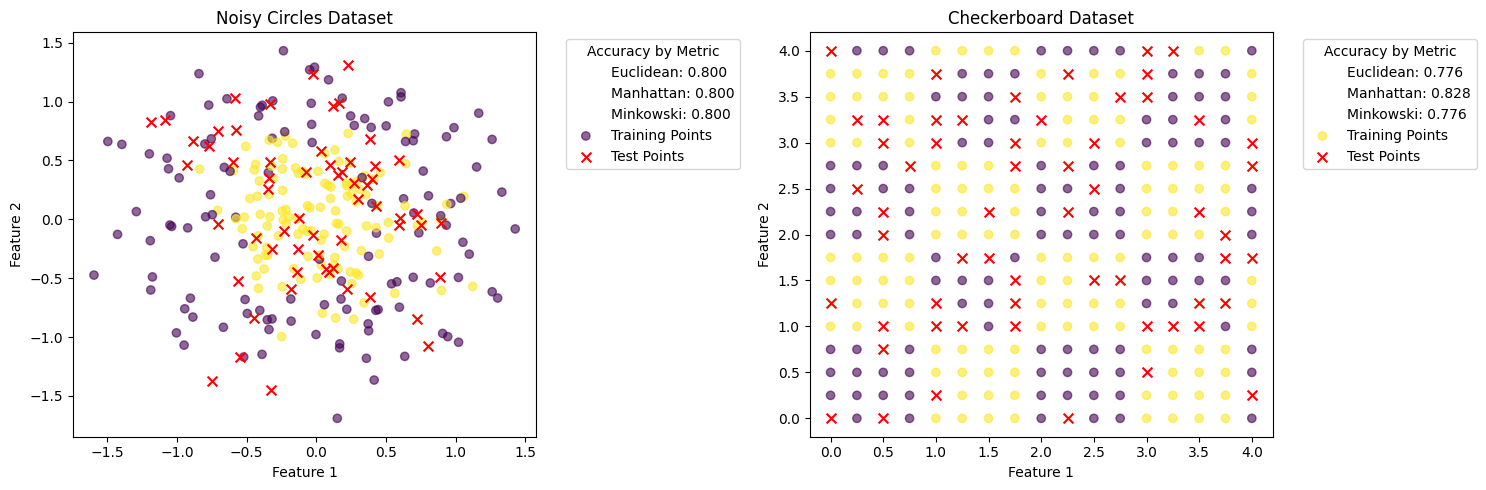

In [7]:
# Dua panel: titik latih diwarnai per kelas, titik uji sebagai silang merah
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

scatter1_train = ax1.scatter(X_circles_train[:, 0], X_circles_train[:, 1], c=y_circles_train, cmap='viridis', alpha=0.6, label='Training Points')
scatter1_test = ax1.scatter(X_circles_test[:, 0], X_circles_test[:, 1], color='red', marker='x', s=50, label='Test Points')
ax1.set_title('Noisy Circles Dataset')
ax1.set_xlabel('Feature 1')  # (tambahan)
ax1.set_ylabel('Feature 2')  # (tambahan)

# Handle tak terlihat agar legenda bisa menampilkan akurasi setiap metrik
lines1 = [plt.Line2D([0], [0], color='white') for _ in metrics]
legend_text1 = [
    f"Euclidean: {results['circles']['euclidean']:.3f}",
    f"Manhattan: {results['circles']['manhattan']:.3f}",
    f"Minkowski: {results['circles']['minkowski']:.3f}"
]
ax1.legend(lines1 + [scatter1_train, scatter1_test], legend_text1 + ['Training Points', 'Test Points'],
          title='Accuracy by Metric', bbox_to_anchor=(1.05, 1), loc='upper left')

scatter2_train = ax2.scatter(X_moons_train[:, 0], X_moons_train[:, 1], c=y_moons_train, cmap='viridis', alpha=0.6, label='Training Points')
scatter2_test = ax2.scatter(X_moons_test[:, 0], X_moons_test[:, 1], color='red', marker='x', s=50, label='Test Points')
ax2.set_title('Checkerboard Dataset')
ax2.set_xlabel('Feature 1')  # (tambahan)
ax2.set_ylabel('Feature 2')  # (tambahan)

lines2 = [plt.Line2D([0], [0], color='white') for _ in metrics]
legend_text2 = [
    f"Euclidean: {results['moons']['euclidean']:.3f}",
    f"Manhattan: {results['moons']['manhattan']:.3f}",
    f"Minkowski: {results['moons']['minkowski']:.3f}"
]
ax2.legend(lines2 + [scatter2_train, scatter2_test], legend_text2 + ['Training Points', 'Test Points'],
          title='Accuracy by Metric', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

> **Catatan:** Empat baris label sumbu yang ditandai `# (tambahan)` tidak ada di kode buku dan ditambahkan hanya agar setiap plot memiliki label sumbu. Satu sel plot di buku juga dipecah menjadi dua sel di sini (menghitung hasil, lalu memplot) agar lebih mudah dibaca. Logikanya tidak berubah.

In [8]:
# Ukuran dataset, orde Minkowski default, dan akurasi sebagai cacahan (tambahan)
print("circles: latih/uji =", len(y_circles_train), "/", len(y_circles_test))
print("checkerboard: titik grid =", len(X_moons), "| latih/uji =", len(y_moons_train), "/", len(y_moons_test))
print("jarak grid =", x[1] - x[0], "| p default 'minkowski' =", KNeighborsClassifier().p)
for data, n_test in [("circles", len(y_circles_test)), ("moons", len(y_moons_test))]:
    print(data, {m: f"{acc:.3f} ({round(acc * n_test)}/{n_test})" for m, acc in results[data].items()})

circles: latih/uji = 240 / 60
checkerboard: titik grid = 289 | latih/uji = 231 / 58
jarak grid = 0.25 | p default 'minkowski' = 2
circles {'euclidean': '0.800 (48/60)', 'manhattan': '0.800 (48/60)', 'minkowski': '0.800 (48/60)'}
moons {'euclidean': '0.776 (45/58)', 'manhattan': '0.828 (48/58)', 'minkowski': '0.776 (45/58)'}


**Interpretasi output.**

* **Euclidean dan Minkowski memberi skor identik pada kedua dataset** (0.800 dan 0.776). Ini memang diharapkan, bukan kebetulan: dengan default `p=2`, Minkowski *adalah* jarak Euclidean, sehingga kedua model menemukan tetangga yang sama.
* **Lingkaran berisik (60 titik uji):** semua metrik mencapai **0.800** (48/60). Dengan `noise=0.3`, cincin dalam dan luar sangat bertumpang tindih (kuning dan ungu bercampur di tengah panel kiri), sehingga sekitar 20 % titik pada dasarnya tidak dapat diprediksi dari tetangganya, apa pun metriknya. Komentar di kode buku mengharapkan Euclidean lebih unggul di sini, tetapi pada eksekusi ini tidak ada perbedaan.
* **Papan catur (289 titik grid, 58 titik uji, jarak grid 0.25):** Manhattan mencetak **0.828** (48/58) vs **0.776** (45/58) untuk Euclidean, yaitu 3 titik uji benar lebih banyak. Petak satuan yang sejajar sumbu menguntungkan metrik yang ketetanggaannya mengikuti sumbu. Namun, banyak tetangga grid yang jaraknya persis sama, sehingga *tie-breaking* juga berperan, dan selisih 3 titik dari 58 sampel adalah bukti yang lemah. Akurasi keseluruhan terbatas karena hanya 3 tetangga yang dipakai dan titik uji yang dikeluarkan dari grid sering berada di batas petak.

### Poin Penting
* Minkowski($p$) menyatukan Manhattan ($p=1$) dan Euclidean ($p=2$), dan `minkowski` default di scikit-learn adalah Euclidean.
* Pada data yang sangat bertumpang tindih (lingkaran berisik), metrik tidak berpengaruh (0.800 untuk semua), karena *noise* membatasi akurasi.
* Pada struktur sejajar sumbu (papan catur), Manhattan sedikit lebih baik (0.828 vs 0.776). Metrik sebaiknya dipilih lewat validasi, bukan kebiasaan.

## Resep 4.3 — *Tuning* Hiperparameter KNN

**Tujuan.** Memilih jumlah tetangga, skema pembobotan, dan metrik jarak untuk *classifier* KNN Iris secara sistematis, memakai *grid search* ber-*cross-validation* alih-alih menebak.

### Teori

**Intuisi.** Hiperparameter (di sini $k$, pembobotan, dan metrik) adalah pengaturan yang dipilih *sebelum* fitting. Memilihnya berdasarkan akurasi data uji akan membuat model *overfit* terhadap data uji, sehingga kita menyimulasikan "data yang belum pernah dilihat" di dalam data latih dengan **k-fold cross-validation**: bagi data latih menjadi $K$ *fold*, latih pada $K-1$ *fold*, validasi pada *fold* sisanya, putar, lalu rata-ratakan. *Grid search* mengulangi proses ini untuk setiap kombinasi nilai kandidat dan mempertahankan yang terbaik.

**Matematika.** Untuk pengaturan hiperparameter $\theta$ dan *fold* $F_1,\dots,F_K$, skor CV-nya adalah
$$\mathrm{CV}(\theta)=\frac{1}{K}\sum_{f=1}^{K}\mathrm{Acc}\big(\hat{h}_{\theta}^{(-f)},F_f\big),$$
dengan $\hat{h}_{\theta}^{(-f)}$ adalah model yang dilatih dengan $\theta$ pada semua *fold* kecuali $F_f$. *Grid search* mengembalikan $\hat\theta=\arg\max_{\theta\in\Theta}\mathrm{CV}(\theta)$ atas grid Kartesius $\Theta$. Di sini $|\Theta|=5\times2\times2=20$ pengaturan × 5 *fold* = **100 kali fitting model**.

**Cara scikit-learn mengimplementasikannya.** `GridSearchCV(estimator, param_grid, scoring=None, cv=None, refit=True, n_jobs=None)`.

* Dengan `cv` berupa bilangan bulat dan sebuah *classifier*, *fold* berasal dari `StratifiedKFold` (proporsi kelas dipertahankan, **tanpa pengacakan**), sehingga hasilnya deterministik.
* Setelah `fit`: `cv_results_` (semua skor), `best_params_`, `best_score_` (rata-rata akurasi CV pemenang), dan `best_estimator_`, yaitu salinan yang di-fit ulang pada **seluruh** data latih karena `refit=True`.
* Skor rata-rata yang seri berbagi peringkat yang sama, dan `best_params_` adalah pengaturan seri pertama menurut urutan grid.

**Asumsi, kelebihan, keterbatasan.**

* Menyeluruh dan sederhana, tetapi biayanya tumbuh secara perkalian setiap kali hiperparameter ditambahkan. `RandomizedSearchCV` atau *successive halving* lebih skalabel.
* `best_score_` bias secara optimis (karena dimaksimalkan), sehingga diperlukan data uji yang disisihkan atau *nested CV* untuk estimasi yang tidak bias.
* Pada dataset kecil, banyak pengaturan hanya berbeda satu sampel yang salah klasifikasi, sehingga pengaturan "terbaik" belum tentu benar-benar lebih baik.

### Kode

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

# Estimator dasar yang belum di-tuning
knn = KNeighborsClassifier()

# 5 x 2 x 2 = 20 pengaturan kandidat
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# CV stratified 5-fold pada data latih, diskor dengan akurasi
grid_search = GridSearchCV(
    knn, param_grid, cv=5, scoring='accuracy'
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.9916666666666668


In [10]:
# Puncak papan peringkat: seberapa dekat posisi berikutnya? (tambahan)
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res["params"] = cv_res["params"].astype(str)
with pd.option_context("display.max_colwidth", None):
    display(cv_res[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(8))

,params,mean_test_score,std_test_score,rank_test_score
6,"{'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}",0.991667,0.016667,1
7,"{'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'distance'}",0.991667,0.016667,1
0,"{'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'uniform'}",0.983333,0.020412,3
1,"{'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'distance'}",0.983333,0.020412,3
3,"{'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance'}",0.983333,0.020412,3
2,"{'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'uniform'}",0.983333,0.020412,3
5,"{'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'distance'}",0.983333,0.020412,3
4,"{'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'uniform'}",0.983333,0.020412,3


**Interpretasi output.** *Grid search* memilih **jarak Euclidean, $k=9$, bobot seragam**, dengan rata-rata akurasi CV 5-fold **0.9917**. Papan peringkat menunjukkan bahwa "kemenangan" ini tipis: `weights="distance"` dengan $k=9$ seri persis (keduanya peringkat 1), dan enam pengaturan berikutnya ($k=3,5,7$ dengan pembobotan mana pun) semuanya bernilai 0.9833. Setiap *fold* validasi berisi 24 bunga, sehingga 0.9917 vs 0.9833 adalah **satu bunga salah klasifikasi dari 120**. Bobot seragam dilaporkan hanya karena muncul lebih dulu di grid. Kesimpulan praktisnya, KNN pada Iris tahan terhadap pilihan-pilihan ini, dan $k$ moderat dengan jarak Euclidean adalah default yang baik.

### Poin Penting
* `GridSearchCV` mengevaluasi setiap kombinasi dengan k-fold CV (di sini 100 kali fitting) dan mem-fit ulang yang terbaik pada seluruh data latih.
* Terbaik: Euclidean, $k=9$, seragam, akurasi CV 0.9917, seri dengan pembobotan jarak.
* Pada data kecil, selisih satu sampel adalah hal biasa, jadi lihat seluruh papan peringkat, bukan hanya `best_params_`.

## Resep 4.4 — Mengevaluasi Kinerja KNN

**Tujuan.** Melampaui satu angka akurasi: mengestimasi stabilitas model hasil *tuning* dengan *cross-validation*, mendiagnosis bias/variansi dengan kurva belajar, dan memeriksa kelas mana yang tertukar dengan *confusion matrix* dan metrik per kelas.

### Teori

**Intuisi.** Satu angka akurasi menyembunyikan banyak hal: seberapa besar variasinya antarpembagian data, apakah data tambahan akan membantu, dan apakah kesalahan tersebar merata atau terpusat pada satu kelas. Setiap alat di bawah menjawab salah satu pertanyaan tersebut.

**Matematika.** Untuk kelas $c$, hitung *true positive* $TP_c$ (diprediksi $c$, memang $c$), *false positive* $FP_c$ (diprediksi $c$, padahal bukan), dan *false negative* $FN_c$ (sebenarnya $c$, diprediksi lain). Maka
$$\text{precision}_c=\frac{TP_c}{TP_c+FP_c},\qquad \text{recall}_c=\frac{TP_c}{TP_c+FN_c},\qquad F_{1,c}=\frac{2\,\text{precision}_c\,\text{recall}_c}{\text{precision}_c+\text{recall}_c}.$$
**Macro average** adalah rata-rata tanpa bobot atas semua kelas. **Weighted average** membobot setiap kelas dengan *support*-nya $n_c$ (jumlah sampel sebenarnya). **Confusion matrix** $C$ berisi $C_{ij}$ = jumlah sampel dengan kelas sebenarnya $i$ yang diprediksi sebagai kelas $j$, sehingga diagonalnya memuat prediksi yang benar. **Kurva belajar** memplot skor latih dan validasi terhadap ukuran data latih $m$: celah besar yang menetap menandakan variansi tinggi (*overfitting*), sedangkan dua kurva rendah yang sudah bertemu menandakan bias tinggi (*underfitting*).

**Cara scikit-learn mengimplementasikannya.**

* `cross_val_score(estimator, X, y, cv=5)` mengembalikan satu skor per *fold* (*fold* stratified tanpa pengacakan untuk *classifier*).
* `learning_curve(estimator, X, y, train_sizes, cv=5)` melatih model pada potongan awal yang makin besar dari setiap *fold* latih dan mengembalikan `train_sizes`, `train_scores`, `test_scores` (bentuk: ukuran × *fold*).
* Baris `confusion_matrix(y_true, y_pred)` adalah kelas sebenarnya dan kolomnya kelas prediksi, dalam urutan label terurut.
* `classification_report(..., output_dict=True)` mengembalikan *precision/recall/F1/support* per kelas ditambah `accuracy`, `macro avg`, dan `weighted avg`.

**Asumsi, kelebihan, keterbatasan.**

* Dengan hanya 30 sampel uji, setiap kesalahan klasifikasi menggeser metrik kelas cukup besar, sehingga angka per kelas berisik.
* Skor *cross-validation* pada data latih memakai *fold* yang sama dengan *grid search*, sehingga optimis untuk model hasil *tuning*.
* Kurva belajar pada potongan data yang sangat kecil bisa didominasi artefak (misalnya $k$ lebih besar dari jumlah sampel per kelas).

### Kode

In [11]:
from sklearn.model_selection import learning_curve, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

Buku menjalankan semua evaluasi dalam satu sel. Di sini sel itu dipecah menjadi empat sel (skor CV → kurva belajar → *confusion matrix* → laporan) tanpa mengubah kodenya, agar setiap output bisa diinterpretasikan tepat di sebelahnya.

In [12]:
# Stabilitas model hasil tuning di 5 fold data latih
cv_scores = cross_val_score(grid_search.best_estimator_, X_train, y_train, cv=5)
print("Cross-validation scores:", cv_scores)
print("Mean CV score:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation scores: [0.95833333 1.         1.         1.         1.        ]
Mean CV score: 0.9916666666666668
Standard deviation: 0.016666666666666653


**Interpretasi output.** Model hasil *tuning* mencetak **0.958 pada *fold* pertama dan 1.000 pada empat *fold* lainnya**: rata-rata **0.9917**, simpangan baku **0.0167**. Satu *fold* yang tidak sempurna berisi satu bunga latih yang salah diklasifikasikan model. Angka ini persis mengulang `best_score_` dari *grid search*, karena `cross_val_score` memakai *fold* stratified deterministik yang sama.

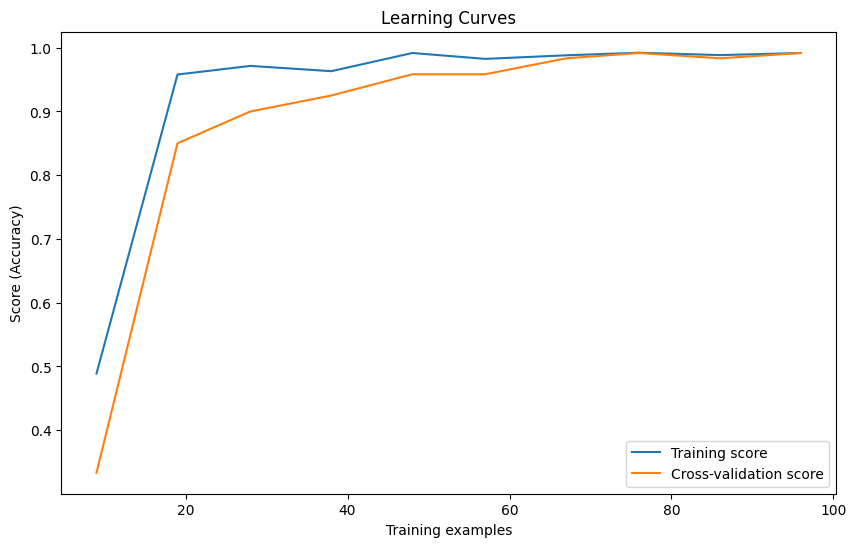

In [13]:
# Akurasi latih vs validasi seiring bertambahnya data latih (10%..100% dari setiap fold)
train_sizes, train_scores, test_scores = learning_curve(
    grid_search.best_estimator_, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5
)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, np.mean(train_scores, axis=1), label='Training score')
plt.plot(train_sizes, np.mean(test_scores, axis=1), label='Cross-validation score')
plt.xlabel('Training examples')
plt.ylabel('Score (Accuracy)')
plt.legend(loc='best')
plt.title('Learning Curves')
plt.show()

In [14]:
# Angka di balik kurva belajar (tambahan)
pd.DataFrame({"ukuran_latih": train_sizes,
              "akurasi_latih": train_scores.mean(axis=1).round(3),
              "akurasi_cv": test_scores.mean(axis=1).round(3)}).T

,0,1,2,3,4,5,6,7,8,9
ukuran_latih,9.000,19.000,28.000,38.000,48.000,57.000,67.000,76.000,86.000,96.000
akurasi_latih,0.489,0.958,0.971,0.963,0.992,0.982,0.988,0.992,0.988,0.992
akurasi_cv,0.333,0.850,0.900,0.925,0.958,0.958,0.983,0.992,0.983,0.992


**Interpretasi output.**

* **Pada 9 contoh latih**, skornya hanya 0.489 (latih) dan 0.333 (CV). Dengan $k=9$ dan tepat 9 titik tersimpan, *setiap* kueri memiliki 9 tetangga yang sama, sehingga model memprediksi satu kelas untuk semuanya, kira-kira akurasi sepertiga pada tiga kelas yang seimbang. Ini artefak karena $k$ sebesar ukuran data latih, bukan sifat KNN pada Iris.
* **Mulai dari 19 contoh**, kedua kurva melonjak (0.958 / 0.850) dan terus naik. Akurasi validasi mencapai 0.958 pada 48 contoh dan **0.992 pada 96**, sama dengan kurva latih (0.992).
* Kedua kurva **bertemu tanpa celah** dan skor latih tidak pernah mencapai 1.0, karena $k=9$ menghaluskan aturan keputusan alih-alih menghafal titik. Inilah ciri model dengan variansi rendah dan bias rendah pada masalah ini. Data tambahan hanya akan sedikit membantu.

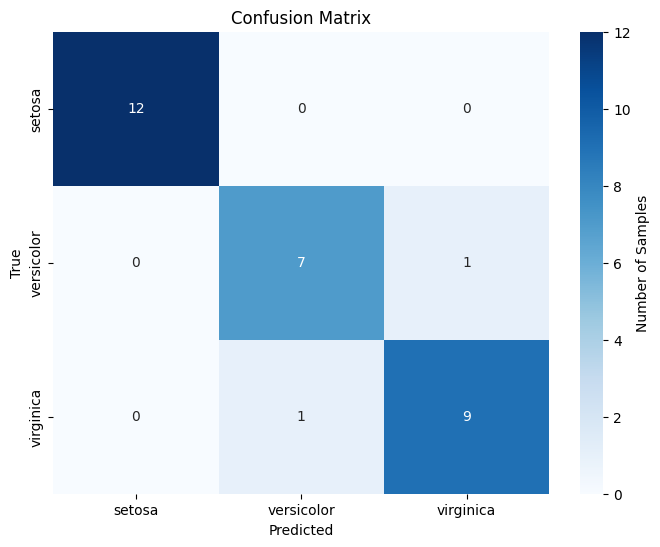

In [15]:
# Prediksi data uji yang disisihkan dengan model hasil tuning
y_pred = grid_search.best_estimator_.predict(X_test)

class_names = iris.target_names

# Heatmap confusion matrix (baris = sebenarnya, kolom = prediksi)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

**Interpretasi output.** Pada 30 bunga uji, model hasil *tuning* membuat **2 kesalahan**: satu versicolor diprediksi sebagai virginica dan satu virginica diprediksi sebagai versicolor. Ke-**12 setosa** benar semua tanpa kekeliruan ke arah mana pun. Hal ini mencerminkan geometri Iris yang sudah dikenal: setosa dapat dipisahkan secara linear dari dua spesies lainnya, sedangkan versicolor dan virginica bertumpang tindih pada ukuran kelopak dan mahkotanya.

In [16]:
# Precision / recall / F1 per kelas sebagai tabel bergaya
report_dict = classification_report(y_test, y_pred,
                                  target_names=class_names,
                                  output_dict=True)

report_df = pd.DataFrame(report_dict).transpose()

styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print("\nClassification Report:")
display(styled_df)


Classification Report:


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,12
versicolor,0.875,0.875,0.875,8
virginica,0.900,0.900,0.900,10
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.925,0.925,30
weighted avg,0.933,0.933,0.933,30


**Interpretasi output.**

* **setosa:** *precision* = *recall* = F1 = **1.000** (12/12).
* **versicolor:** 7 dari 8 ditemukan (*recall* 0.875), dan 7 dari 8 bunga yang diprediksi versicolor memang benar (*precision* 0.875).
* **virginica:** 9 dari 10 ditemukan (*recall* 0.900), *precision* 0.900.
* **Akurasi keseluruhan = 0.933** (28/30), sama dengan model 3-NN tanpa *tuning* di Resep 4.1. *Tuning* menaikkan akurasi CV tetapi tidak mengubah akurasi uji pada pembagian kecil ini.
* Baris `accuracy` mengulang 0.933 di setiap kolom, dan sel `support`-nya menampilkan "1". Ini artefak tampilan: `classification_report` menyimpan akurasi sebagai satu angka, sehingga DataFrame menyebarkannya ke seluruh baris dan format `{:.0f}` membulatkan 0.933 menjadi 1.
* Skor setosa yang sempurna tidak menandakan *overfitting* di sini: kurva belajar tidak menunjukkan celah latih/validasi, dan setosa memang mudah dipisahkan.

### Poin Penting
* Skor CV (rata-rata 0.9917, simpangan baku 0.0167) menunjukkan model hasil *tuning* stabil di seluruh *fold*.
* Kurva belajar menunjukkan kurva latih/validasi yang bertemu tanpa celah (variansi rendah). Titik pertamanya terdistorsi karena $k$ sama dengan ukuran data latih.
* Kedua kesalahan uji adalah kekeliruan versicolor ↔ virginica, sedangkan setosa terpisah sempurna.
* *Precision*, *recall*, dan F1 per kelas mengungkap *di mana* model gagal, hal yang disembunyikan satu angka akurasi.

## Resep 4.5 — Latihan Praktis Model KNN

**Tujuan.** Menerapkan alur kerja KNN lengkap (penskalaan → fit → prediksi → evaluasi, ditambah *grid search*) pada tiga masalah baru: satu dataset medis biner nyata dan dua dataset sintetis tiga kelas.

### Teori

Ketiga latihan menstandardisasi fitur dengan `StandardScaler` yang di-fit hanya pada bagian data latih, lalu menerapkannya pada data uji. Untuk KNN langkah ini sangat penting: fitur Breast Cancer berkisar dari pecahan (*smoothness* ≈ 0,1) hingga ribuan (*area*), dan tanpa penskalaan jaraknya hampir seluruhnya ditentukan oleh "area". Tugas sintetis berasal dari `make_classification(n_samples, n_features, n_informative, n_redundant, n_classes, n_clusters_per_class)`. Fungsi ini menempatkan klaster Gaussian untuk setiap kelas di titik-titik sudut sebuah *hypercube* dalam subruang berdimensi `n_informative`, menambahkan `n_redundant` fitur sebagai kombinasi linear acak dari fitur informatif, dan mengisi sisanya dengan *noise*. Dimensi redundan dan *noise* mengencerkan jarak KNN (*curse of dimensionality*), itulah sebabnya tugas ini lebih sulit daripada Iris. Latihan 3 juga mencetak *confusion matrix*, dengan definisi yang sama seperti di Resep 4.4.

### Kode — Latihan 1: Membangun Classifier KNN (biner, Breast Cancer)

In [17]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# 569 tumor, 30 fitur; target 0 = ganas (malignant), 1 = jinak (benign)
data = load_breast_cancer()
X = data.data
y = data.target

# Pembagian 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Statistik penskalaan hanya berasal dari bagian data latih
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.947

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        43
           1       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



**Interpretasi output.** 5-NN pada fitur terstandardisasi mengklasifikasikan **94,7 %** dari 114 tumor uji dengan benar (108/114). Kesalahannya cukup seimbang: kelas 0 (ganas, 43 sampel) memiliki *precision* = *recall* = **0.93**, dan kelas 1 (jinak, 71 sampel) **0.96**. Dalam konteks medis, *recall* kelas ganas paling penting: 0.93 berarti sekitar 3 dari 43 tumor ganas terlewat, biaya yang tidak terlihat dari akurasi saja.

### Kode — Latihan 2: Tuning Hiperparameter dengan Grid Search (sintetis, 3 kelas)

In [18]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# 1.000 sampel, 20 fitur (15 informatif, 5 redundan), 3 kelas
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15,
                         n_redundant=5, n_classes=3, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Grid 20 pengaturan yang sama seperti Resep 4.3
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
knn = KNeighborsClassifier()
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')

grid_search.fit(X_train_scaled, y_train)

# Hasil CV pemenang, lalu kinerjanya pada data uji yang belum disentuh
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)
y_pred = grid_search.predict(X_test_scaled)
print("\nTest Set Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.8574999999999999

Test Set Performance:
Accuracy: 0.88

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.86      0.89        70
           1       0.91      0.96      0.93        73
           2       0.79      0.81      0.80        57

    accuracy                           0.88       200
   macro avg       0.88      0.87      0.87       200
weighted avg       0.88      0.88      0.88       200



**Interpretasi output.** Grid kembali memilih **Euclidean, $k=9$, bobot seragam**, dengan akurasi CV **0.8575**. Pada 200 sampel uji, model yang di-fit ulang mencapai **0.88**, sedikit di atas estimasi CV-nya, yang merupakan variasi sampling yang wajar. Akurasinya jauh lebih rendah daripada Iris karena ruang 20-D dengan 15 dimensi informatif membuat ketetanggaan kurang murni. Kelas 2 adalah yang tersulit (F1 **0.80**), dibandingkan 0.89 dan 0.93 untuk kelas 0 dan 1.

### Kode — Latihan 3: Mengevaluasi Classifier KNN (sintetis, 3 kelas)

In [19]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1.000 sampel, 15 fitur (10 informatif, 5 redundan), 3 kelas masing-masing 2 klaster
X, y = make_classification(n_samples=1000,
                         n_features=15,
                         n_informative=10,
                         n_redundant=5,
                         n_classes=3,
                         n_clusters_per_class=2,
                         random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

# Akurasi, confusion matrix, dan laporan per kelas
print("Model Performance Evaluation")
print("-" * 30)
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.3f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Performance Evaluation
------------------------------
Accuracy Score: 0.850

Confusion Matrix:
[[56  6  6]
 [ 4 56  5]
 [ 6  3 58]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.82      0.84        68
           1       0.86      0.86      0.86        65
           2       0.84      0.87      0.85        67

    accuracy                           0.85       200
   macro avg       0.85      0.85      0.85       200
weighted avg       0.85      0.85      0.85       200



**Interpretasi output.** Model 5-NN tanpa *tuning* mencapai akurasi uji **85,0 %** (170/200). Diagonal *confusion matrix* (56, 56, 58) memuat prediksi yang benar. Ke-30 kesalahan tersebar di semua sel di luar diagonal, yang terbesar adalah kelas 0 diprediksi sebagai 1 atau 2 (masing-masing 6) dan kelas 2 diprediksi sebagai 0 (6). Tidak ada satu pasangan kelas yang mendominasi kekeliruan, dan skor F1 per kelas mirip (0.84, 0.86, 0.85). Inilah yang diharapkan dari kelas sintetis yang simetris, berbeda dengan Iris yang semua kesalahannya versicolor ↔ virginica.

### Poin Penting
* Penskalaan sebelum KNN sangat penting pada data nyata. Dengan penskalaan, 5-NN mencapai 94,7 % pada Breast Cancer.
* Pada data sintetis yang lebih sulit, *grid search* kembali memilih Euclidean / $k=9$ / seragam (CV 0.8575, uji 0.88).
* *Confusion matrix* menunjukkan *bagaimana* kesalahan tersebar: merata untuk kelas sintetis yang simetris, terpusat untuk kelas nyata yang bertumpang tindih.

## Ringkasan Bab

| Resep | Konsep | Kelas/fungsi sklearn utama | Poin penting |
|---|---|---|---|
| 4.1 Memahami KNN | Suara terbanyak dari $k$ titik latih terdekat | `KNeighborsClassifier` | 3-NN mencapai 93,3 % pada Iris. "Pelatihan" hanya menyimpan data. |
| 4.2 Metrik Jarak | Keluarga Minkowski ($p=1$ Manhattan, $p=2$ Euclidean) | argumen `metric=` | `minkowski` default = Euclidean. Manhattan membantu pada data sejajar sumbu (0.828 vs 0.776); *noise* membatasi lingkaran di 0.800. |
| 4.3 *Tuning* Hiperparameter | Pencarian menyeluruh yang diskor dengan k-fold CV | `GridSearchCV` | Terbaik = Euclidean, $k=9$, seragam (CV 0.9917), seri dengan pembobotan jarak. Selisih satu sampel adalah hal biasa. |
| 4.4 Mengevaluasi KNN | Stabilitas CV, kurva belajar, *confusion matrix*, *precision/recall/F1* | `cross_val_score`, `learning_curve`, `confusion_matrix`, `classification_report` | Kurva bertemu (variansi rendah). Kedua kesalahan uji adalah versicolor ↔ virginica. |
| 4.5 Latihan Praktis | Penskalaan → fit → *tuning* → evaluasi pada data baru | `StandardScaler`, `GridSearchCV`, `make_classification` | 94,7 % pada Breast Cancer; 85–88 % pada tugas sintetis 3 kelas yang lebih sulit. |

**Kaitan dengan Bab 5.** KNN bersifat *non-parametrik*: ia menyimpan data dan tidak pernah meringkasnya dengan parameter. Bab 5 beralih ke ekstrem yang berlawanan, yaitu **model linear parametrik**, yang memampatkan data menjadi satu bobot per fitur. Bab itu kemudian memperkenalkan **regularisasi** (Ridge, Lasso, ElasticNet), jenis hiperparameter lain yang di-*tuning* dengan alat *cross-validation* yang sama seperti yang dipelajari di sini.

## Referensi

* Sukup, J. (2025). *scikit-learn Cookbook, Third Edition*. Packt Publishing. Bab 4.
* Repositori kode resmi: <https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition>
* scikit-learn User Guide — Nearest Neighbors: <https://scikit-learn.org/1.5/modules/neighbors.html>
* scikit-learn API — `DistanceMetric` (metrik yang tersedia): <https://scikit-learn.org/1.5/modules/generated/sklearn.metrics.DistanceMetric.html>
* scikit-learn User Guide — Tuning the hyper-parameters of an estimator: <https://scikit-learn.org/1.5/modules/grid_search.html>
* scikit-learn User Guide — Cross-validation: <https://scikit-learn.org/1.5/modules/cross_validation.html>
* scikit-learn User Guide — Validation curves and learning curves: <https://scikit-learn.org/1.5/modules/learning_curve.html>
* scikit-learn User Guide — Classification metrics: <https://scikit-learn.org/1.5/modules/model_evaluation.html#classification-metrics>